In [384]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.metrics import (mean_absolute_error, 
                        mean_squared_error, 
                        r2_score)

pd.set_option("display.max_columns", 200)
sns.set_style('whitegrid')

In [362]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

In [363]:
train_df.head()

,id,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,total_sales
0,row_00000,PRD-PRFP9S,14.252,Low Fat,0.0271,Frozen Foods,81.37,STORE-AGY,45,Large,Tier_3,Standard Supermarket,1764.98
1,row_00001,PRD-PXXK71,7.698,Low Fat,0.0720,HEALTH AND HYGIENE,42.05,STORE-YLW,35,Small,Tier_1,Standard Supermarket,342.13
2,row_00002,PRD-V5MOIJ,14.264,Regular,0.0421,Canned,41.35,STORE-89Z,33,Medium,Tier_1,Standard Supermarket,378.85
3,row_00003,PRD-UN5Z3J,NaN,Regular,0.0449,soft drinks,174.35,STORE-7WS,47,Medium,Tier_3,Flagship Hypermarket,5595.72
4,row_00004,PRD-6RDQYB,10.338,Regular,0.0120,meat,203.06,STORE-9RG,28,Small,Tier_2,Standard Supermarket,2375.36


We'll have to encode fat_content, store_size (missing values), store_location_tier, store_format, possibly Product_category

In [364]:
train_df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 6818 entries, 0 to 6817
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   6818 non-null   str    
 1   product_code         6818 non-null   str    
 2   product_weight_kg    5593 non-null   float64
 3   fat_content          6818 non-null   str    
 4   shelf_visibility     6818 non-null   float64
 5   product_category     6818 non-null   str    
 6   product_price        6818 non-null   float64
 7   store_code           6818 non-null   str    
 8   store_age_years      6818 non-null   int64  
 9   store_size           4899 non-null   str    
 10  store_location_tier  6818 non-null   str    
 11  store_format         6818 non-null   str    
 12  total_sales          6818 non-null   float64
dtypes: float64(4), int64(1), str(8)
memory usage: 692.6 KB


From the info, we have missing values in product_weight_kg and store-size

In [365]:
train_df.describe()

,product_weight_kg,shelf_visibility,product_price,store_age_years,total_sales
count,5593.000000,6818.000000,6818.000000,6818.000000,6818.000000
mean,12.850876,0.065527,140.473623,34.178205,2174.756574
std,4.646542,0.051566,62.413513,8.384574,1697.894956
min,4.482000,0.000000,31.110000,23.000000,32.700000
25%,8.750000,0.026600,93.280000,28.000000,834.792500
50%,12.647000,0.053200,142.065000,33.000000,1790.890000
75%,16.894000,0.093400,185.987500,45.000000,3092.587500
max,21.883000,0.320100,273.040000,47.000000,12996.820000


In [366]:
print(train_df["store_format"].value_counts(), "\n")
print(train_df["fat_content"].value_counts(), "\n")
print(train_df["store_size"].value_counts(), "\n")
print(train_df["store_location_tier"].value_counts())

# pd.DataFrame({
#     'count': df.count(),
#     'min': df.min(),
#     'max': df.max()
# })

store_format
Standard Supermarket    4462
Corner Shop              866
Flagship Hypermarket     748
Superstore               742
Name: count, dtype: int64 

fat_content
Low Fat    4425
Regular    2393
Name: count, dtype: int64 

store_size
Medium    2218
Small     1933
Large      748
Name: count, dtype: int64 

store_location_tier
Tier_3    2677
Tier_2    2232
Tier_1    1909
Name: count, dtype: int64


In [367]:
# for store-location-tier, we can easily convert to numerical values only
# train_df["store_location_tier"] = train_df["store_location_tier"].str[-1]

# this cant work because tier_3 is smaller towns

In [368]:
print(train_df["product_category"].value_counts(), "\n")
# some are recurring but are in different cases or spelling
# Snack Foods vs snack foods  vs SNACK FOODS  
# fruits and vegetables  vs FRUITS AND VEGETABLES  vs Fruits and Vegetables
# frozen foods vs Frozen Foods  vs   FROZEN FOODS 
# dairy vs DAIRY
# Household vs HOUSEHOLD vs household
# Baking Goods vs BAKING GOODS  vs baking goods  And then there's "Breads vs BREADS vs breads" in a separate category
# meat vs MEAT vs Meat
# hard drinks  vs HARD DRINKS   vs Hard Drinks  vs 
# canned vs CANNED 
# SEAFOOD  vs seafood 
# Soft Drinks vs    SOFT DRINKS     vs soft drinks
# canned vs CANNED
# Health and Hygiene    vs health and hygiene   vs HEALTH AND HYGIENE
# seafood vs SEAFOOD    vs Seafood    
# Starchy Foods     vs STARCHY FOODS   vs starchy foods
# others vs Others  vs OTHERS                    
# Breakfast     vs breakfast

# but even this is about 17 categories


product_category
Fruits and Vegetables    480
Snack Foods              468
Household                387
Frozen Foods             326
Canned                   271
Dairy                    269
fruits and vegetables    265
FRUITS AND VEGETABLES    261
Baking Goods             254
snack foods              236
SNACK FOODS              229
Health and Hygiene       197
HOUSEHOLD                185
Soft Drinks              178
frozen foods             177
FROZEN FOODS             172
household                168
Meat                     157
DAIRY                    143
dairy                    142
BAKING GOODS             137
canned                   129
baking goods             125
CANNED                   117
health and hygiene       116
Breads                   110
SOFT DRINKS              100
HEALTH AND HYGIENE        99
MEAT                      94
Hard Drinks               92
soft drinks               88
meat                      88
Others                    73
Starchy Foods             

In [1]:
result = train_df.groupby('store_code')[['store_size', 'store_location_tier', 'store_format']].agg(lambda x: x.unique().tolist()).reset_index()

print(result)


NameError: name 'train_df' is not defined

<Axes: xlabel='store_age_years', ylabel='total_sales'>

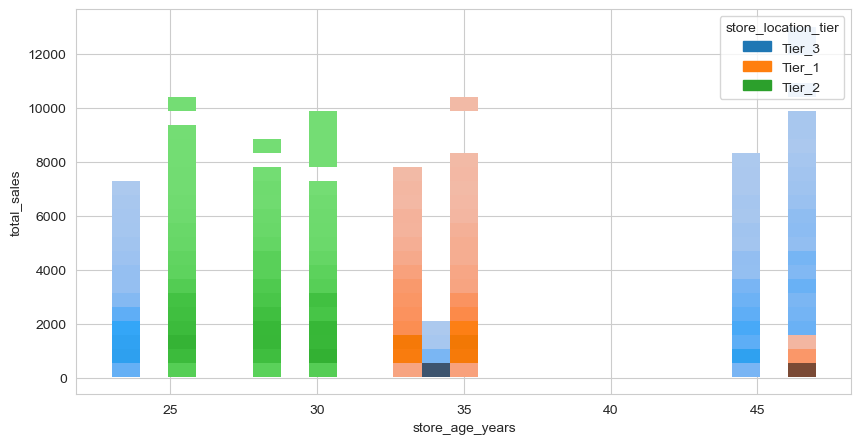

In [369]:
plt.figure(figsize=(10,5))

sns.histplot(data=train_df, x="store_age_years", y="total_sales", hue="store_location_tier", bins=25)

In [370]:
# I want to try standardizing the text in the product_category column to make it easier to analyze. I will convert all the text to lowercase and remove any accidental whitespace.
train_df['product_category'] = train_df['product_category'].str.lower()
train_df['product_category'] = train_df['product_category'].str.strip().str.lower()
train_df['product_category'].value_counts()

product_category
fruits and vegetables    1006
snack foods               933
household                 740
frozen foods              675
dairy                     554
canned                    517
baking goods              516
health and hygiene        412
soft drinks               366
meat                      339
breads                    209
hard drinks               169
others                    132
starchy foods             113
breakfast                  85
seafood                    52
Name: count, dtype: int64

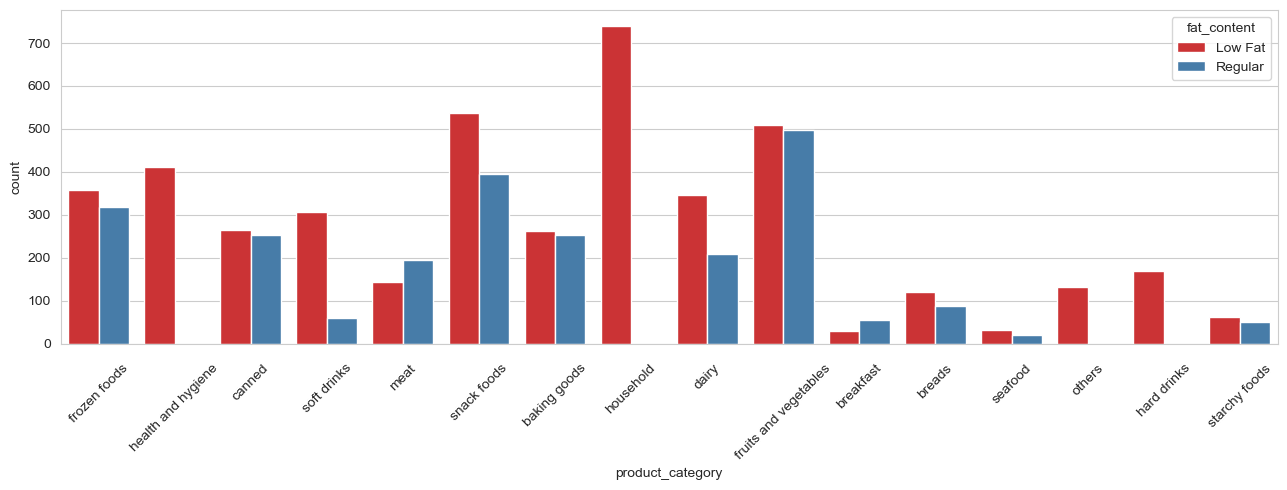

In [371]:
plt.figure(figsize=(13,5))
graph = sns.countplot(x='product_category', hue='fat_content',data=train_df,palette='Set1')
# y= "total_sales",

graph.tick_params(axis='x', labelrotation=45, pad=10)
plt.tight_layout()

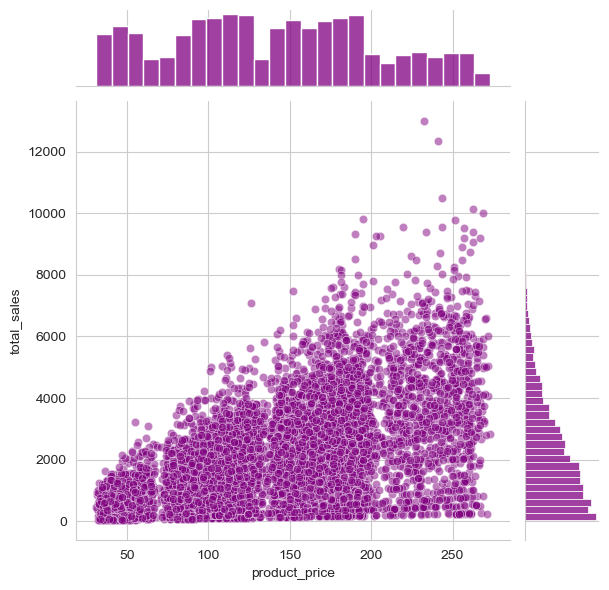

In [372]:
sns.jointplot(x='product_price',y='total_sales',data=train_df,color='purple', alpha=0.5)

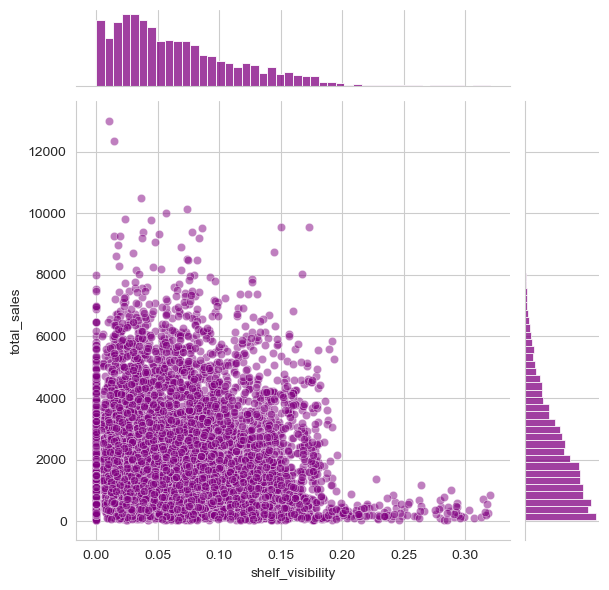

In [373]:
sns.jointplot(x='shelf_visibility',y='total_sales',data=train_df,color='purple',  alpha=0.5)

So product price has an almost linear relationship with total sales. 
But shelf_visibility has an inverse relationship. And it looks like 0 points to teh most visible shelfs

In [374]:
train_df[['product_weight_kg', "shelf_visibility", "product_price", "store_age_years", "total_sales"]].corr()

,product_weight_kg,shelf_visibility,product_price,store_age_years,total_sales
product_weight_kg,1.000000,-0.013986,0.034824,0.009020,0.015532
shelf_visibility,-0.013986,1.000000,0.003905,0.071078,-0.118124
product_price,0.034824,0.003905,1.000000,-0.012747,0.569833
store_age_years,0.009020,0.071078,-0.012747,1.000000,0.039443
total_sales,0.015532,-0.118124,0.569833,0.039443,1.000000


From the correlation, product price has a strong relationship with total_sales, which confirms 
what our graph says. 

<Axes: >

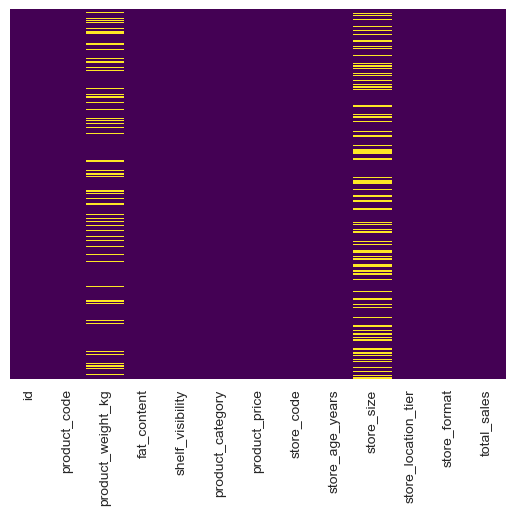

In [375]:
sns.heatmap(train_df.isnull(),yticklabels=False,cbar=False,cmap='viridis')

<Axes: xlabel='store_location_tier', ylabel='store_size'>

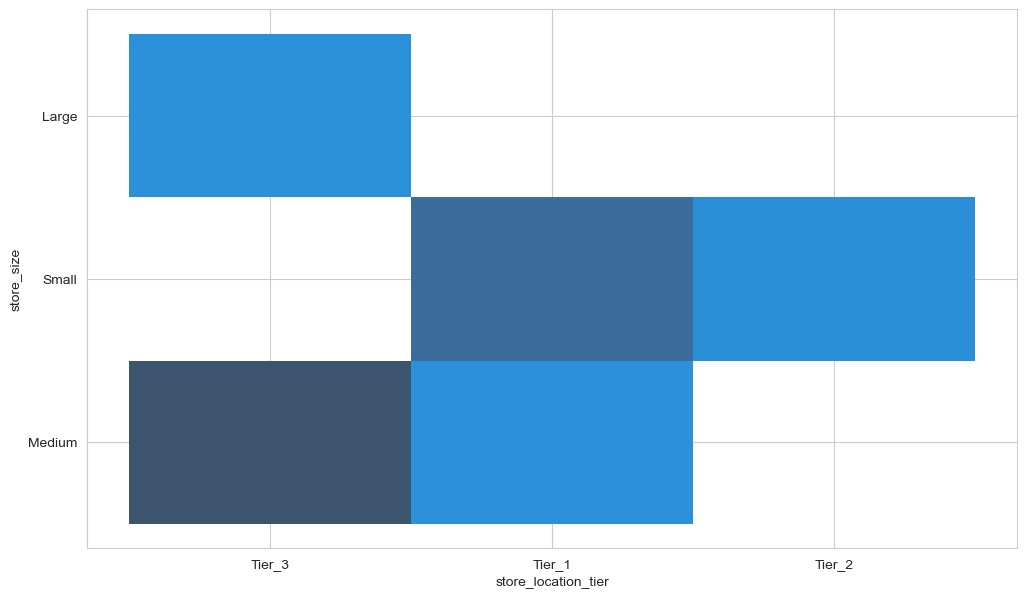

In [376]:
# I need something that has strong relationship with store_size
####### AI: store_format, and store_location_tier. I will try to see if there is a relationship between store_age_years and total_sales. I will also try to see if there is a relationship between product_price and total_sales. I will also try to see if there is a relationship between shelf_visibility and total_sales. I will also try to see if there is a relationship between product_weight_kg and total_sales. I will also try to see if there is a relationship between product_category and total_sales. I will also try to see if there is a relationship between fat_content and total_sales. I will also try to see if there is a relationship between store_size and total_sales. I will also try to see if there is a relationship between store_format and total_sales. I will also try to see if there is a relationship between store_location_tier and total_sales.
plt.figure(figsize=(12, 7))
sns.histplot(y='store_size',x='store_location_tier',data=train_df)

<Axes: xlabel='store_size', ylabel='store_format'>

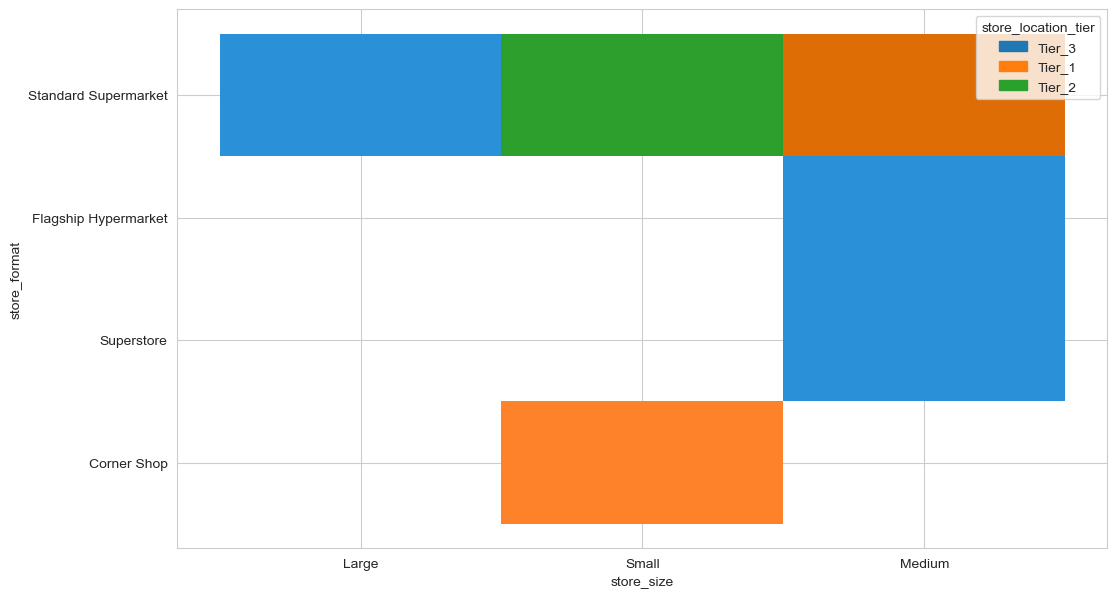

In [377]:
plt.figure(figsize=(12, 7))
sns.histplot(x='store_size',y='store_format',data=train_df, hue='store_location_tier')

In [378]:

def impute_store_size(row):
    store_size = row["store_size"]
    store_format = row["store_format"]
    store_location_tier = row["store_location_tier"]

    if pd.isnull(store_size):

        if store_format == "Standard Supermarket" and store_location_tier == "Tier_3":
            return "Large"

        elif (store_format == "Standard Supermarket" and store_location_tier == "Tier_1"):
            return "Medium"
        
        elif (store_format == "Standard Supermarket" and store_location_tier == "Tier_2"):
            return "Small"

        elif (store_format == "Flagship Hypermarket" or store_format == "Superstore") and store_location_tier == "Tier_3":
            return "Medium"
        
        else:
            return np.nan

    else:
        return store_size


train_df["store_size"] = train_df.apply(impute_store_size, axis=1)
test_df["store_size"] = test_df.apply(impute_store_size, axis=1)

In [380]:
train_df["store_size"].isnull().sum()
# wait

np.int64(439)

In [ ]:
print(train_df["store_format"].value_counts(), "\n")
print(train_df["fat_content"].value_counts(), "\n")
print(train_df["store_size"].value_counts(), "\n")
print(train_df["store_location_tier"].value_counts())
# We'll have to encode fat_content, store_size (missing values), store_location_tier, store_format, possibly Product_category

store_format
Standard Supermarket    4462
Corner Shop              866
Flagship Hypermarket     748
Superstore               742
Name: count, dtype: int64 

fat_content
Low Fat    4425
Regular    2393
Name: count, dtype: int64 

store_size
Small     3413
Medium    2218
Large      748
Name: count, dtype: int64 

store_location_tier
Tier_3    2677
Tier_2    2232
Tier_1    1909
Name: count, dtype: int64


In [ ]:
# store-size didnt work below so I want to check the unique values since I know it has missing values
train_df["store_size"].unique()

<StringArray>
['Large', 'Small', 'Medium', nan]
Length: 4, dtype: str

In [ ]:

train_df["store_size"] =train_df["store_size"].fillna("unknown")

train_df["store_size"].isnull().sum()


np.int64(0)

In [ ]:
# train_df["store_size"] =train_df["store_size"].fillna("unknown")

train_df["store_location_tier"].isnull().sum()


np.int64(0)

In [ ]:
# So I want to try converting some of the categorical variables to numerical values.
# For the ones that have hierarchy, I will use mapping. For the others, I will use one-hot encoding.

# For store_format
store_format = pd.get_dummies(train_df["store_format"], drop_first=True, dtype=int)

# for fat_content
fat_content = pd.get_dummies(train_df["fat_content"], drop_first=True, dtype=int)

# For store_size
train_df["store_size_num"] = train_df["store_size"].str.lower().str.strip().map({
    "unknown": -1, "small": 0,   "medium": 1,    "large": 2  })

# For store_location_tier
train_df["store_location_tier_num"] = train_df["store_location_tier"].str.lower().str.strip().map({
    "tier_3": 0,   "tier_2": 2,    "tier_1": 3 })

# train_df["store_size"]


In [381]:
# Now i do this for the test data as well
# For store_format
store_format = pd.get_dummies(test_df["store_format"], drop_first=True, dtype=int)

# for fat_content
fat_content = pd.get_dummies(test_df["fat_content"], drop_first=True, dtype=int)

# For store_size
test_df["store_size_num"] = test_df["store_size"].str.lower().str.strip().map({
    "unknown": -1, "small": 0,   "medium": 1,    "large": 2  })

# For store_location_tier
test_df["store_location_tier_num"] = test_df["store_location_tier"].str.lower().str.strip().map({
    "tier_3": 0,   "tier_2": 2,    "tier_1": 3 })

In [382]:
# wait
# train_df.drop(columns=["store_format"])
# train_df


train_df=train_df.drop(columns=["store_format", "fat_content", "store_size", "store_location_tier"])
train_df = pd.concat([train_df, fat_content, store_format], axis=1)

test_df=test_df.drop(columns=["store_format", "fat_content", "store_size", "store_location_tier"])
test_df = pd.concat([test_df, fat_content, store_format], axis=1)

In [ ]:
train_df.head()

,id,product_code,product_weight_kg,shelf_visibility,product_category,product_price,store_code,store_age_years,total_sales,store_size_num,store_location_tier_num,Regular,Flagship Hypermarket,Standard Supermarket,Superstore
0,row_00000,PRD-PRFP9S,14.252,0.0271,frozen foods,81.37,STORE-AGY,45,1764.98,2,0,0,0,1,0
1,row_00001,PRD-PXXK71,7.698,0.0720,health and hygiene,42.05,STORE-YLW,35,342.13,0,3,0,0,1,0
2,row_00002,PRD-V5MOIJ,14.264,0.0421,canned,41.35,STORE-89Z,33,378.85,1,3,1,0,1,0
3,row_00003,PRD-UN5Z3J,NaN,0.0449,soft drinks,174.35,STORE-7WS,47,5595.72,1,0,1,1,0,0
4,row_00004,PRD-6RDQYB,10.338,0.0120,meat,203.06,STORE-9RG,28,2375.36,0,2,1,0,1,0


In [391]:
X = train_df.drop(columns=["id", "product_code", "product_weight_kg", "product_category", "store_code", "total_sales"])
y = train_df["total_sales"]

X_train, X_val, y_train, y_val = train_test_split(X,y, test_size=0.25, random_state=42)

In [401]:
rfr = RandomForestRegressor(n_estimators=100, random_state=42)
rfr.fit(X_train, y_train)

# Generate predictions using the unseen validation data
rfr_prediction = rfr.predict(X_val)


In [402]:
# Mean Absolute Error (MAE) measures the average size of the prediction errors
MAE = mean_absolute_error(y_val, rfr_prediction)
print(f'The Mean Absolute Error is: {MAE}')

# Root Mean Squared Error (RMSE) measures error size while penalizing larger mistakes
RMSE = np.sqrt(mean_squared_error(y_val, rfr_prediction))
print(f'The Root Mean Squared Error is: {RMSE}')

The Mean Absolute Error is: 950.759020234604
The Root Mean Squared Error is: 1313.894945279409


In [ ]:
######## Up Next: Proper data cleaning and feature engineering. Also consider median for product weight. Maybe mode for market tier